In [ ]:
from code_utils import *
import numpy as np
import matplotlib.pyplot as plt 

In [2]:
# LS  + Rogers/Haugh/Kogan

#  value_ls != V_1 rispetto a LS quindi se faccio la media ottengo V_1 non il valore iniziale dell'opzione
# In order to learn the "kink" an idea could be to add the (S - K)^+ as a non linearity


# The training paths are used to determine the value fo the american option, the continuation value and therefore
# the optimal stopping rule and the estimate of the lower bound. Given that the upper bound estimated through Rogers/Haugh/Kogan
# used the value and the continuation value in order to determine the martingale for the dual approach, we are going to use the same
# paths in order to determine the upper bound!


# Parameters
K = 100 			# Strike price
sigma = 0.3 		# Volatility 
r = 0.05 			# Risk-free rate
q = 0 				# Dividend yield
mu = r - q 		# Drift 
T = 0.2   			# Maturity  
dt = 0.004 			# Time step 
N = int(T / dt) 	# Number of steps 

seed = 42 				# Random seed for reproducibility
seed_weights = 12345 	# Random seed for the weights in the basis functions

npaths_train = 10**5 	# Number of paths for estimating the coefficients of the regression 
npaths_pricing = 10**5	# Number of paths for estimating the price of the option 

nneurons = 4 			# Degree of the polynomial basis for regression
sigma_basis = sigma 	# Standard deviation for the random weights in the basis functions


real_prices = np.array([40.00000000, 39.00000000, 38.00000000, 37.00000000, 36.00000000, 35.00000000, 34.00000000, 33.00000000, 32.00000000, 31.00000000,
                        30.00000000, 29.00000000, 28.00000000, 27.00000000, 26.00000000, 25.00000000, 24.00000000, 23.00000000, 22.00000000, 21.00000000,
                        20.00070685, 19.01347004, 18.04313091, 17.09109638, 16.15883366, 15.24783858, 14.35960625, 13.49560169, 12.65723381, 11.84582143,
                        11.06257234, 10.30856320, 9.58471980, 8.89180771, 8.23041673, 7.60094690, 7.00361025, 6.43844700, 5.90532237, 5.40390521,
                        4.93370425, 4.49410547, 4.08432251, 3.70344748, 3.35050142, 3.02435964, 2.72386986, 2.44779995, 2.19486933, 1.96380311,
                        1.75326609, 1.56197956, 1.38862261, 1.23195119, 1.09070376, 0.96370545, 0.84978944, 0.74786820, 0.65689777, 0.57588855,
                        0.50392803, 0.44013960, 0.38373063, 0.33395543, 0.29012326, 0.25161274, 0.21784490, 0.18829301, 0.16248633, 0.13999277,
                        0.12042199, 0.10342780, 0.08869869, 0.07595400, 0.06494518, 0.05545341, 0.04728321, 0.04026147, 0.03423616, 0.02907429,0.02465918 ])


# Paths simulation : The first two Montecarlo are merely used for determining the lower bound
train_ls = simulate_gbm(mu, sigma, T, dt, npaths_train, seed=seed)
test_ls = simulate_gbm(mu, sigma, T, dt, npaths_pricing, seed=seed + 1)

train_reg = simulate_gbm(mu, sigma, T, dt, npaths_train, seed = seed + 2)
price_set = simulate_gbm(mu, sigma, T, dt, npaths_pricing, seed = seed + 3)

# Applying transformation

stats = fit_log_standardizer(train_ls)          
train_ls_log = apply_log_standardizer(train_ls, stats)
test_ls_log = apply_log_standardizer(test_ls, stats)

stats_reg = fit_log_standardizer(train_reg)
train_reg_log = apply_log_standardizer(train_reg, stats_reg)
price_log = apply_log_standardizer(price_set, stats_reg)


# Discount factors for each time step
discount_factors = np.exp(-r * np.arange(0, N + 1) * dt) 

# Precomputing the basis for the regression since after transformation the input doesn't depend on S0
basis_train_ls_mod, weights_train = random_basis(train_ls_log[1:N,:], nneurons, sigma_basis, seed=seed_weights)
basis_test_ls_mod, _ = random_basis(test_ls_log[1:N,:], nneurons, sigma_basis, seed=seed_weights, weights=weights_train)

basis_train_reg_mod, _ = random_basis(train_reg_log[1:N,:], nneurons, sigma_basis, seed=seed_weights, weights=weights_train)
basis_pricing_mod, _ = random_basis(price_log[1:N,:], nneurons, sigma_basis, seed=seed_weights, weights=weights_train)

# Adjusting the shape of the basis 
basis_train_ls= basis_train_ls_mod.transpose(1, 2, 0)
basis_test_ls = basis_test_ls_mod.transpose(1, 2, 0)

basis_train_reg = basis_train_reg_mod.transpose(1, 2, 0)
basis_price = basis_pricing_mod.transpose(1, 2, 0)

coefficients = {}
train_deg = {}
lower_bound = np.empty(81)
#uncertainty_ls = np.empty(81)
#percentage_error_ls = np.empty(81)

upper_bound_rhg_values = np.empty(81)
uncertainty_rhg = np.empty(81)
percentage_error_rhg = np.empty(81)

for S0 in np.arange(60,141):
    # First Montecarlo : determining the coefficient for estimating the continuation value for ITM paths

    lower_bound[S0-60], _, coefficients[S0], _, _, _  = lower_bound_ls(K, S0, T, dt, train_ls, test_ls, discount_factors, npaths_train, npaths_pricing, nneurons, basis_train_ls, basis_test_ls)
    price = lower_bound[S0-60]
    coefficients_cont_value_itm = coefficients[S0] # Coefficients for estimating the continuation value for ITM paths
    
    # Computing the continuation value for ITM and OTM paths, hence for all paths!
    Z_reg = np.maximum(0, K - S0 * train_reg) * discount_factors[:, np.newaxis]
    V_tilde_reg = np.zeros((N+1, npaths_train))
    V_tilde_reg[0,:] = price
    V_tilde_reg[-1,:] = Z_reg[-1,:]
    coefficients_reg = np.zeros((N-1, nneurons + 1 ))
    Q_tilde_reg = np.zeros((N-1, npaths_train)) # E_1[V_2], ..., E_{N-1}[V_N]
    for t in range(N - 1, 0, -1):
        value = V_tilde_reg[t+1,:]
        vander_full = basis_train_reg[t-1, :, :] # the t-1 is given by the shape of basis_train_reg
        itm = Z_reg[t,:] > 0
        # Regression to compute the value of the option and E_k[V_{k+1}] ( we are not restricting to ITM paths )
        coefficients_reg[t-1,:], _, _, _ = np.linalg.lstsq(vander_full, value, rcond=None) 
        continuation_value_itm = basis_train_reg[t-1,:,:] @ coefficients_cont_value_itm[t-1,:] 
        Q_tilde_reg[t-1,:] = basis_train_reg[t-1,:,:] @ coefficients_reg[t-1,:]
        # What is actually happening in the condition is the following : if we are ITM, then we can use the continuation value using 
        # the coefficient determined using LS since they have been computed using only the ITM paths!
        V_tilde_reg[t, : ]= np.where( itm & (Z_reg[t,:] > continuation_value_itm), Z_reg[t,:], Q_tilde_reg[t-1,:])
        # What we are computing here is actually the value of the american option at time t
    
    # To avoid overfitting we use another Montercarlo to compute the value, the continuation value and the respective martingale
    Z = np.maximum(0, K - S0 * price_set) * discount_factors[:, np.newaxis] 
    V_tilde = np.zeros((N+1, npaths_pricing)) # V_0, ..., V_N
    V_tilde[0,:] = price
    V_tilde[-1,:] = Z[-1,:]
    Q_tilde = np.zeros((N, npaths_pricing)) # E_0[V_1], E_1[V_2], ..., E_{N-1}[V_N]
    
    for t in range(N-1, 0, -1):
        vander_full = basis_price[t-1, :, :] # the t-1 is given by the shape of basis_train_reg
        itm = Z[t,:] > 0
        cont_value_itm = basis_price[t-1,:,:] @ coefficients_cont_value_itm[t-1,:] 
        Q_tilde[t,:] = basis_price[t-1,:,:] @ coefficients_reg[t-1,:]
        V_tilde[t, : ]= np.where( itm & (Z[t,:] > cont_value_itm), Z[t,:], Q_tilde[t,:])
    Q_tilde[0,:] = V_tilde[1,:].mean()

    # Computing the martingale
    martingale = np.zeros((N+1, npaths_pricing)) 
    martingale[0,:] = price
    for i in range(N):
        martingale[i+1,:] = martingale[i,:] + V_tilde[i+ 1 ,:] - Q_tilde[i,:]

    # Second Montecarlo : determining the coefficient for the estimating E_t[ V_{t+1} - V_t ] 

    # Upper bound
    maximizing = price + np.max(Z - martingale, axis=0)
    antithetic_sum = (maximizing[:npaths_pricing//2] + maximizing[npaths_pricing//2:]) / 2
    option_price = np.mean(antithetic_sum)

    upper_bound_rhg_values[S0-60] = option_price
    uncertainty_rhg[S0-60] = np.std(antithetic_sum, ddof=1) / np.sqrt(npaths_pricing//2)

    # Printing the percentage error wrt the real price
    #percentage_error_ls[S0-60] = np.abs(lower_bound[S0-60] - real_prices[S0 - 60]) / real_prices[S0 - 60] * 100
    #print(f"S0= {S0}, Lower Bound Price: {lower_bound[S0-60]:.5f}, Real Price: {real_prices[S0-60]:.5f}, Percentage Error: {percentage_error_ls[S0-60]:.2f}%, Uncertainty: {uncertainty_ls[S0-60]:.5f}")
    percentage_error_rhg[S0-60] = np.abs(upper_bound_rhg_values[S0-60] - real_prices[S0 - 60]) / real_prices[S0 - 60] * 100
    print(f"S0= {S0}, Upper Bound Price: {upper_bound_rhg_values[S0-60]:.5f}, Real Price: {real_prices[S0-60]:.5f}, Percentage Error: {percentage_error_rhg[S0-60]:.2f}%, Uncertainty: {uncertainty_rhg[S0-60]:.5f}")



S0= 60, Upper Bound Price: 40.01285, Real Price: 40.00000, Percentage Error: 0.03%, Uncertainty: 0.00020
S0= 61, Upper Bound Price: 39.01505, Real Price: 39.00000, Percentage Error: 0.04%, Uncertainty: 0.00025
S0= 62, Upper Bound Price: 38.01546, Real Price: 38.00000, Percentage Error: 0.04%, Uncertainty: 0.00029
S0= 63, Upper Bound Price: 37.01542, Real Price: 37.00000, Percentage Error: 0.04%, Uncertainty: 0.00035
S0= 64, Upper Bound Price: 36.01723, Real Price: 36.00000, Percentage Error: 0.05%, Uncertainty: 0.00041
S0= 65, Upper Bound Price: 35.01756, Real Price: 35.00000, Percentage Error: 0.05%, Uncertainty: 0.00050
S0= 66, Upper Bound Price: 34.01856, Real Price: 34.00000, Percentage Error: 0.05%, Uncertainty: 0.00060
S0= 67, Upper Bound Price: 33.01778, Real Price: 33.00000, Percentage Error: 0.05%, Uncertainty: 0.00071
S0= 68, Upper Bound Price: 32.01969, Real Price: 32.00000, Percentage Error: 0.06%, Uncertainty: 0.00081
S0= 69, Upper Bound Price: 31.02349, Real Price: 31.000

In [ ]:
np.savez('rnn_upper_rogers_results.npz', S0=np.arange(60,141), price=upper_bound_rhg_values, error=percentage_error_rhg, uncertainty=uncertainty_rhg)

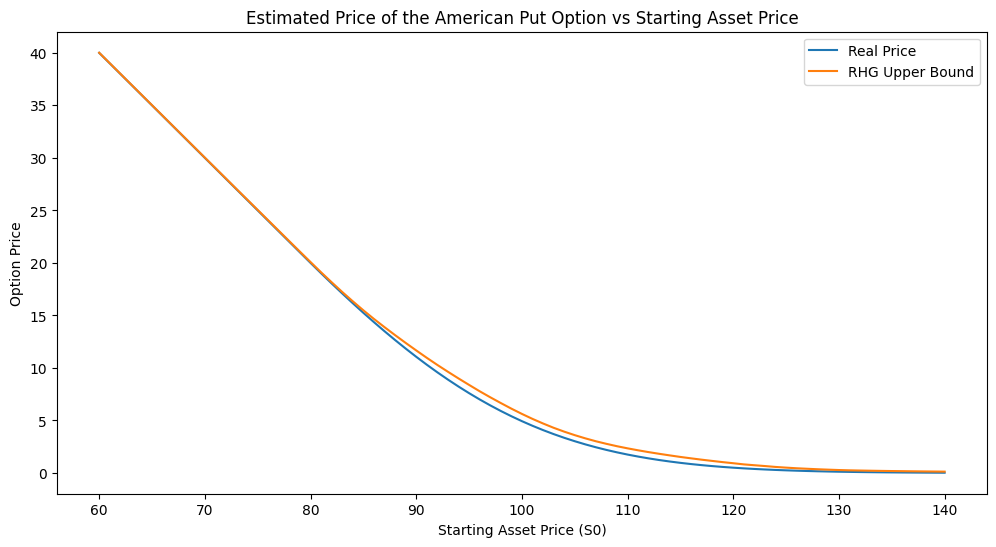

In [5]:
# Plotting the results 
plt.figure(figsize=(12, 6))
plt.plot(np.arange(60,141), real_prices, label='Real Price')
#plt.plot(np.arange(60,141), lower_bound, label='LS Lower Bound', color='blue', linestyle='--')
plt.plot(np.arange(60,141), upper_bound_rhg_values, label='RHG Upper Bound')
plt.title('Estimated Price of the American Put Option vs Starting Asset Price')
plt.xlabel('Starting Asset Price (S0)')
plt.ylabel('Option Price')
plt.legend()

In [7]:
def rnn_upper_bound_american_put_rhg(K, S0, T, dt, r, q, sigma, seed, npaths_train, npaths_pricing, nneurons, sigma_basis, seed_weights):
	N = int(T / dt) 	# Number of steps
	mu = r - q
	# Paths simulation : The first two Montecarlo are merely used for determining the lower bound
	train_ls = simulate_gbm(mu, sigma, T, dt, npaths_train, seed=seed)
	test_ls = simulate_gbm(mu, sigma, T, dt, npaths_pricing, seed=seed + 1)

	train_reg = simulate_gbm(mu, sigma, T, dt, npaths_train, seed = seed + 2)
	price_set = simulate_gbm(mu, sigma, T, dt, npaths_pricing, seed = seed + 3)

	# Applying transformation
	stats = fit_log_standardizer(train_ls)          
	train_ls_log = apply_log_standardizer(train_ls, stats)
	test_ls_log = apply_log_standardizer(test_ls, stats)

	stats_reg = fit_log_standardizer(train_reg)
	train_reg_log = apply_log_standardizer(train_reg, stats_reg)
	price_log = apply_log_standardizer(price_set, stats_reg)

	# Discount factors for each time step
	discount_factors = np.exp(-r * np.arange(0, N + 1) * dt) 

	# Precomputing the basis for the regression since after transformation the input doesn't depend on S0
	basis_train_ls_mod, weights_train = random_basis(train_ls_log[1:N,:], nneurons, sigma_basis, seed=seed_weights)
	basis_test_ls_mod, _ = random_basis(test_ls_log[1:N,:], nneurons, sigma_basis, seed=seed_weights, weights=weights_train)

	basis_train_reg_mod, _ = random_basis(train_reg_log[1:N,:], nneurons, sigma_basis, seed=seed_weights, weights=weights_train)
	basis_pricing_mod, _ = random_basis(price_log[1:N,:], nneurons, sigma_basis, seed=seed_weights, weights=weights_train)

	# Adjusting the shape of the basis 
	basis_train_ls= basis_train_ls_mod.transpose(1, 2, 0)
	basis_test_ls = basis_test_ls_mod.transpose(1, 2, 0)

	basis_train_reg = basis_train_reg_mod.transpose(1, 2, 0)
	basis_price = basis_pricing_mod.transpose(1, 2, 0)

	price_estimate, uncertainty_estimate = upper_bound_rhg(K, S0, T, dt, N, train_ls, test_ls, train_reg, price_set, discount_factors, npaths_train, npaths_pricing, nneurons, basis_train_ls, basis_test_ls, basis_train_reg, basis_price)
	return price_estimate, uncertainty_estimate

In [11]:
# Parameters
K = 100 			# Strike price
sigma = 0.3 		# Volatility 
r = 0.05  			# Risk-free rate
q = 0 				# Dividend yield
mu = r - q  		# Drift 
T = 0.2   			# Maturity  
dt = 0.004 			# Time step 
N = int(T / dt) 	# Number of steps 

seed = 42 				# Random seed for reproducibility
seed_weights = 12345 	# Random seed for the weights in the basis functions

npaths_train = 10**5 	# Number of paths for estimating the coefficients of the regression 
npaths_pricing = 10**5	# Number of paths for estimating the price of the option 

nneurons = 4 			# Degree of the polynomial basis for regression
sigma_basis = sigma 	# Standard deviation for the random weights in the basis functions


real_prices = np.array([40.00000000, 39.00000000, 38.00000000, 37.00000000, 36.00000000, 35.00000000, 34.00000000, 33.00000000, 32.00000000, 31.00000000,
                        30.00000000, 29.00000000, 28.00000000, 27.00000000, 26.00000000, 25.00000000, 24.00000000, 23.00000000, 22.00000000, 21.00000000,
                        20.00070685, 19.01347004, 18.04313091, 17.09109638, 16.15883366, 15.24783858, 14.35960625, 13.49560169, 12.65723381, 11.84582143,
                        11.06257234, 10.30856320, 9.58471980, 8.89180771, 8.23041673, 7.60094690, 7.00361025, 6.43844700, 5.90532237, 5.40390521,
                        4.93370425, 4.49410547, 4.08432251, 3.70344748, 3.35050142, 3.02435964, 2.72386986, 2.44779995, 2.19486933, 1.96380311,
                        1.75326609, 1.56197956, 1.38862261, 1.23195119, 1.09070376, 0.96370545, 0.84978944, 0.74786820, 0.65689777, 0.57588855,
                        0.50392803, 0.44013960, 0.38373063, 0.33395543, 0.29012326, 0.25161274, 0.21784490, 0.18829301, 0.16248633, 0.13999277,
                        0.12042199, 0.10342780, 0.08869869, 0.07595400, 0.06494518, 0.05545341, 0.04728321, 0.04026147, 0.03423616, 0.02907429,0.02465918 ])

for S0 in np.arange(60,141):
    price, standard_error = rnn_upper_bound_american_put_rhg(K, S0, T, dt, r, q, sigma, seed, npaths_train, npaths_pricing, nneurons, sigma_basis, seed_weights)
    percentage_error_rhg = np.abs(price - real_prices[S0 - 60]) / real_prices[S0 - 60] * 100
    print(f"S0= {S0}, Upper Bound Price: {price:.5f}, Real Price: {real_prices[S0-60]:.5f}, Percentage Error: {percentage_error_rhg:.2f}%, Uncertainty: {standard_error:.5f}")
                                          


S0= 60, Upper Bound Price: 40.01285, Real Price: 40.00000, Percentage Error: 0.03%, Uncertainty: 0.00020
S0= 61, Upper Bound Price: 39.01505, Real Price: 39.00000, Percentage Error: 0.04%, Uncertainty: 0.00025
S0= 62, Upper Bound Price: 38.01546, Real Price: 38.00000, Percentage Error: 0.04%, Uncertainty: 0.00029
S0= 63, Upper Bound Price: 37.01542, Real Price: 37.00000, Percentage Error: 0.04%, Uncertainty: 0.00035
S0= 64, Upper Bound Price: 36.01723, Real Price: 36.00000, Percentage Error: 0.05%, Uncertainty: 0.00041
S0= 65, Upper Bound Price: 35.01756, Real Price: 35.00000, Percentage Error: 0.05%, Uncertainty: 0.00050
S0= 66, Upper Bound Price: 34.01856, Real Price: 34.00000, Percentage Error: 0.05%, Uncertainty: 0.00060
S0= 67, Upper Bound Price: 33.01778, Real Price: 33.00000, Percentage Error: 0.05%, Uncertainty: 0.00071
S0= 68, Upper Bound Price: 32.01969, Real Price: 32.00000, Percentage Error: 0.06%, Uncertainty: 0.00081
S0= 69, Upper Bound Price: 31.02349, Real Price: 31.000